### 1. Import Library dan Konfigurasi Ekstraksi Fitur
Sel ini bertugas mengimpor library PyTorch untuk model Pretrained CNN, PCA dari Scikit-Learn untuk reduksi dimensi, serta konfigurasi visualisasi.


In [ ]:
import os
import sys
from pathlib import Path
import cv2                 
import numpy as np         
import pandas as pd        
from PIL import Image      
from tqdm.auto import tqdm 
import torch                          
import torchvision.models as models   
import torchvision.transforms as transforms 
from sklearn.decomposition import PCA      
from sklearn.preprocessing import normalize 
import matplotlib.pyplot as plt
import seaborn as sns


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110


### 2. Setup Path dan Pemuatan Citra Bersih Hasil Tahap 1
Sel ini bertugas menentukan lokasi folder citra bersih `citra_preprocessed` dan memuat daftar citra dari `data_ukiran.csv`.


In [ ]:
# Setup Jalur Direktori secara Adaptif
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "kode_program":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Menentukan lokasi folder input dan output
DATASET_DIR = PROJECT_ROOT / "dataset" / "BaliCarving"
OUTPUT_DIR = PROJECT_ROOT / "output_data"
PREPROCESSED_DIR = OUTPUT_DIR / "citra_preprocessed" 
CSV_PATH = OUTPUT_DIR / "data_ukiran.csv"

# Verifikasi ketersediaan file metadata dari Tahap 1
if not CSV_PATH.exists():
    raise FileNotFoundError(f"File {CSV_PATH} belum ditemukan! Jalankan '01_preprocessing.ipynb' terlebih dahulu.")

df_ukiran = pd.read_csv(CSV_PATH)
print(f"Data ukiran berhasil dimuat: {len(df_ukiran)} citra.")

# Memilih folder input citra: Prioritaskan citra bersih hasil prapemrosesan Tahap 1
if PREPROCESSED_DIR.exists() and len(list(PREPROCESSED_DIR.glob('*.jpg'))) > 0:
    INPUT_IMAGE_DIR = PREPROCESSED_DIR
    print(f"Menggunakan citra bersih hasil Tahap 1 dari: {INPUT_IMAGE_DIR}")
else:
    INPUT_IMAGE_DIR = DATASET_DIR / "JPEGImages"
    print(f"Peringatan: Folder citra preprocessed belum terisi. Mengambil dari citra asli: {INPUT_IMAGE_DIR}")

# Deteksi ketersediaan GPU (CUDA) untuk mempercepat komputasi model CNN
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Perangkat komputasi yang digunakan: {device}")


Data ukiran berhasil dimuat: 2364 citra.
Menggunakan citra bersih hasil Tahap 1 dari: D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\citra_preprocessed
Perangkat komputasi yang digunakan: cpu


### 3. Inisialisasi Model Ekstraktor Fitur Pretrained CNN (MobileNetV2)
Sel ini bertugas memuat arsitektur Pretrained CNN dengan memotong layer klasifikasi akhir untuk menghasilkan representasi vektor semantik berdimensi tinggi.


In [ ]:
class FeatureExtractorCNN:
    def __init__(self, model_name='mobilenet_v2', device='cpu'):
        self.device = device
        self.model_name = model_name
        
        print(f"Memuat arsitektur model {model_name}...")
        try:
            # Memuat bobot pretrained ImageNet bawaan TorchVision
            if model_name == 'mobilenet_v2':
                weights = models.MobileNet_V2_Weights.DEFAULT
                base_model = models.mobilenet_v2(weights=weights)
                self.feature_dim = 1280
                # Memotong classification head, hanya mengambil convolutional features + pooling
                self.features = base_model.features
                self.pool = torch.nn.AdaptiveAvgPool2d((1, 1))
            elif model_name == 'resnet50':
                weights = models.ResNet50_Weights.DEFAULT
                base_model = models.resnet50(weights=weights)
                self.feature_dim = 2048
                self.features = torch.nn.Sequential(*list(base_model.children())[:-1])
                self.pool = torch.nn.Identity()
            else:
                raise ValueError(f"Model tidak dikenal: {model_name}")
        except Exception as e:
            # Fallback jika komputer offline / tidak ada koneksi internet
            print(f"Peringatan: Memuat bobot lokal/offline ({e}).")
            if model_name == 'mobilenet_v2':
                base_model = models.mobilenet_v2(weights=None)
                self.feature_dim = 1280
                self.features = base_model.features
                self.pool = torch.nn.AdaptiveAvgPool2d((1, 1))
            else:
                base_model = models.resnet50(weights=None)
                self.feature_dim = 2048
                self.features = torch.nn.Sequential(*list(base_model.children())[:-1])
                self.pool = torch.nn.Identity()

        # Memindahkan model ke perangkat komputasi (GPU atau CPU) dan set mode evaluasi (tidak training)
        self.features.to(self.device)
        self.features.eval()
        
        # Transformasi input standar ImageNet (Resize 224x224, konversi ke Tensor, dan normalisasi z-score)
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def extract(self, img_pil):
        # unsqueeze(0) menambahkan dimensi batch (1, C, H, W)
        tensor = self.transform(img_pil).unsqueeze(0).to(self.device)
        with torch.no_grad(): # Menonaktifkan kalkulasi gradien untuk menghemat memori
            feat = self.features(tensor)
            if hasattr(self, 'pool'):
                feat = self.pool(feat)
            feat = torch.flatten(feat, 1) # Meratakan output menjadi vektor 1D
        return feat.cpu().numpy().flatten()

# Inisialisasi objek ekstraktor fitur
extractor = FeatureExtractorCNN(model_name='mobilenet_v2', device=device)
print(f"Ekstraktor siap dengan dimensi output: {extractor.feature_dim}")


Memuat model mobilenet_v2...
Ekstraktor siap dengan dimensi output: 1280


### 4. Ekstraksi Fitur Citra Bersih Secara Batch
Sel ini bertugas membaca citra yang sudah di-resize dan di-CLAHE pada Tahap 1, lalu menerjemahkannya ke matriks fitur numerik.


In [20]:
# Menyiapkan list untuk menampung seluruh vektor fitur citra
fitur_list = []
valid_indices = []

print(f"Memulai ekstraksi fitur visual dari: {INPUT_IMAGE_DIR}...")

# Perulangan untuk membaca setiap citra yang terdaftar di data_ukiran.csv
for idx, row in tqdm(df_ukiran.iterrows(), total=len(df_ukiran), desc="Ekstraksi Fitur"):
    img_path = INPUT_IMAGE_DIR / row['nama_file']
    if img_path.exists():
        # Membuka citra yang sudah bersih (Resize 224x224 + CLAHE dari Tahap 1)
        pil_img = Image.open(img_path).convert('RGB')
        
        # Ekstraksi representasi semantik citra menjadi vektor numerik
        vec = extractor.extract(pil_img)
        fitur_list.append(vec)
        valid_indices.append(idx)
    else:
        print(f"File tidak ditemukan: {row['nama_file']}")

# Mengubah daftar vektor menjadi matriks 2D NumPy (Jumlah Citra x Jumlah Fitur)
fitur_mentah = np.array(fitur_list, dtype=np.float32)

print("Ekstraksi selesai!")
print(f"Matriks Fitur Mentah: Shape = {fitur_mentah.shape}, Ukuran Memori = {fitur_mentah.nbytes / (1024*1024):.2f} MB")


Memulai ekstraksi fitur visual dari D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\citra_preprocessed...


Ekstraksi Fitur:   0%|          | 0/2364 [00:00<?, ?it/s]

Ekstraksi selesai!
Matriks Fitur Mentah: Shape = (2364, 1280), Ukuran Memori = 11.54 MB


### 5. Normalisasi Vektor Fitur (L2 Normalization)
Sel ini bertugas menstandarkan panjang setiap vektor fitur menjadi 1 agar jarak Euclidean setara dengan Cosine Distance.


In [21]:
# Menerapkan Normalisasi L2 pada Setiap Baris Vektor Fitur
# Rumus: x_norm = x / ||x||_2
# Tujuan: Menyamakan panjang vektor ke bola satuan (unit sphere), sehingga jarak Euclidean
# menjadi setara dengan Cosine Distance dan tidak bias terhadap intensitas cahaya keseluruhan.
fitur_l2 = normalize(fitur_mentah, norm='l2')

print(f"Normalisasi L2 selesai. Bentuk matriks: {fitur_l2.shape}")
print(f"Contoh norma L2 dari baris pertama (seharusnya 1.0000): {np.linalg.norm(fitur_l2[0]):.4f}")


Matriks fitur L2 berhasil disimpan ke: D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\fitur_mentah_l2.npy
Contoh norma L2 dari baris pertama: 1.0000


### 6. Reduksi Dimensi Fitur Menggunakan PCA (50 Komponen Utama)
Sel ini bertugas mereduksi dimensi fitur menjadi 50 komponen utama dan menyimpannya ke format CSV (`output_data/fitur_pca.csv`).


In [22]:
# Menerapkan Principal Component Analysis (PCA) ke 50 Komponen Utama
# Tujuan: Mengatasi 'Curse of Dimensionality', membuang korelasi berlebih, dan mempercepat clustering
n_components = 50
pca = PCA(n_components=n_components, random_state=42)
fitur_pca = pca.fit_transform(fitur_l2)

# 1. Membuat DataFrame dengan Nama Kolom pca_1 sampai pca_50
kolom_pca = [f'pca_{i+1}' for i in range(fitur_pca.shape[1])]
df_pca = pd.DataFrame(fitur_pca, columns=kolom_pca)

# 2. Menggabungkan Identitas Citra (nama_file dan motif_utama) di Kolom Terdepan
df_pca.insert(0, 'motif_utama', df_ukiran['motif_utama'].values)
df_pca.insert(0, 'nama_file', df_ukiran['nama_file'].values)

# 3. Menyimpan Matriks Fitur Lengkap ke File CSV (Mudah dibuka di Excel / Pandas)
pca_csv_path = OUTPUT_DIR / 'fitur_pca.csv'
df_pca.to_csv(pca_csv_path, index=False)

print('Reduksi dimensi selesai!')
print(f'Matriks Fitur PCA berhasil disimpan ke CSV: {pca_csv_path}')
print(f'Ukuran tabel: {df_pca.shape[0]} baris x {df_pca.shape[1]} kolom')

# Menampilkan 5 baris pertama data fitur
df_pca.head(5)


Reduksi dimensi selesai!
Matriks Fitur tersimpan dalam dua format:
  1. CSV : D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\fitur_pca.csv (Tabel dengan 52 kolom)
  2. NPY : D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\fitur_pca.npy (Biner Shape (2364, 50))


,nama_file,motif_utama,pca_1,pca_2,pca_3,pca_4,pca_5,pca_6,pca_7,pca_8,...,pca_41,pca_42,pca_43,pca_44,pca_45,pca_46,pca_47,pca_48,pca_49,pca_50
0,train (1).jpg,Gajah,0.207832,0.055249,-0.065845,-0.156661,-0.104649,-0.270010,0.085941,-0.150519,...,0.157578,0.018003,-0.037243,-0.034715,0.004117,0.001700,-0.003524,-0.002224,0.105444,-0.022860
1,train (2).jpg,Gajah,0.255935,0.044174,-0.040205,-0.182214,-0.064741,-0.265661,0.085095,-0.136557,...,0.159120,0.003858,-0.025428,-0.083407,-0.026608,0.007296,-0.000604,0.035796,0.075492,0.031573
2,train (3).jpg,Gajah,0.178115,0.026579,0.035411,-0.116552,-0.030836,-0.311361,-0.001775,-0.228732,...,0.141116,0.046125,-0.092054,-0.040610,0.024315,0.029465,0.047555,0.028635,0.076438,0.006270
3,train (4).jpg,Barong,0.318317,-0.005752,0.003215,-0.258885,-0.153074,-0.283066,0.095155,0.020870,...,-0.003742,0.057821,-0.033226,-0.022627,-0.130557,0.100017,-0.113418,0.012329,-0.025135,-0.034982
4,train (5).jpg,Barong,0.332614,0.095530,0.003580,-0.250978,-0.137374,-0.295206,0.059325,0.075488,...,-0.004312,0.047908,0.015775,-0.022548,-0.113213,0.080419,-0.153320,-0.021567,-0.049692,-0.039198


### 7. Tabel Ringkasan Perubahan Dimensi dan Ukuran Memori Data
Sel ini bertugas menampilkan tabel perbandingan bentuk matriks, jumlah fitur, dan variansi informasi yang dipertahankan setelah reduksi dimensi.


In [23]:
# Menghitung Total Persentase Variansi yang Berhasil Dipertahankan oleh PCA
total_var = np.sum(pca.explained_variance_ratio_) * 100

# Membuat Tabel Perbandingan Ringkasan Dimensi Data
df_ringkasan_dimensi = pd.DataFrame({
    "Tahapan Pipeline": [
        "1. Ekstraksi Pretrained CNN",
        "2. Normalisasi Vektor L2",
        "3. Reduksi Dimensi PCA (50 Komponen)"
    ],
    "Bentuk Matriks (Shape)": [
        f"({fitur_mentah.shape[0]}, {fitur_mentah.shape[1]})",
        f"({fitur_l2.shape[0]}, {fitur_l2.shape[1]})",
        f"({fitur_pca.shape[0]}, {fitur_pca.shape[1]})"
    ],
    "Jumlah Dimensi": [
        fitur_mentah.shape[1],
        fitur_l2.shape[1],
        fitur_pca.shape[1]
    ],
    "Ukuran Memori": [
        f"{fitur_mentah.nbytes / (1024*1024):.2f} MB",
        f"{fitur_l2.nbytes / (1024*1024):.2f} MB",
        f"{fitur_pca.nbytes / (1024*1024):.2f} MB"
    ],
    "Rasio Kompresi": [
        "1.00x (Basis)",
        "1.00x",
        f"{fitur_mentah.shape[1] / fitur_pca.shape[1]:.1f}x Lebih Ringkas"
    ],
    "Variansi Terjaga": [
        "100.0%",
        "100.0%",
        f"{total_var:.2f}%"
    ]
})

# Menampilkan tabel ringkasan
display(df_ringkasan_dimensi)


,Tahapan Pipeline,Bentuk Matriks (Shape),Jumlah Dimensi,Ukuran Memori,Rasio Kompresi,Variansi Terjaga
0,1. Ekstraksi Pretrained CNN,"(2364, 1280)",1280,11.54 MB,1.00x (Basis),100.0%
1,2. Normalisasi Vektor L2,"(2364, 1280)",1280,11.54 MB,1.00x,100.0%
2,3. Reduksi Dimensi PCA (50 Komponen),"(2364, 50)",50,0.45 MB,25.6x Lebih Ringkas,82.53%


### 8. Visualisasi Grafik Cumulative Explained Variance PCA
Sel ini bertugas menampilkan kurva persentase variansi kumulatif yang berhasil dipertahankan oleh 50 komponen utama PCA.


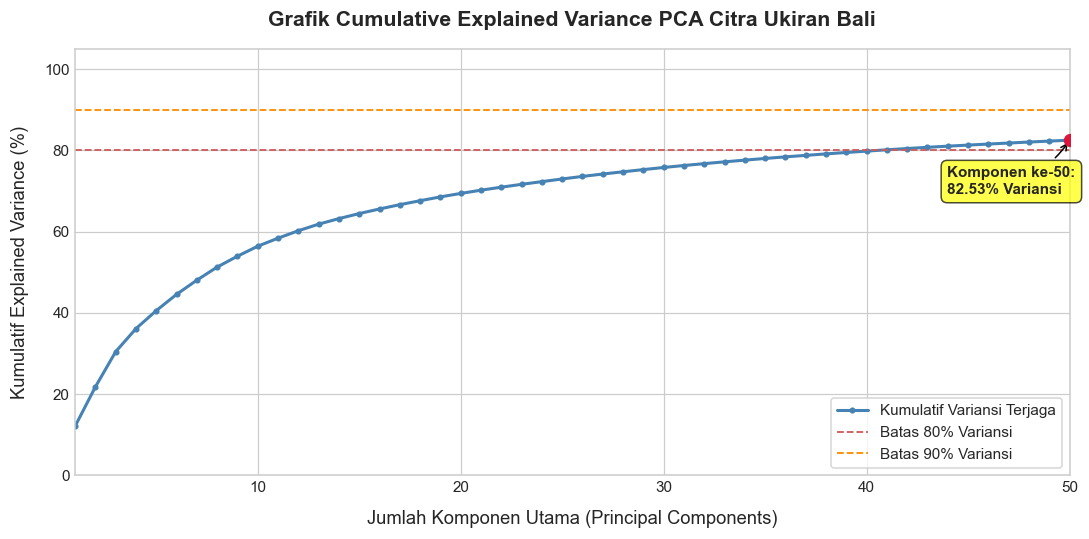

In [24]:
# Menghitung Akumulasi Persentase Variansi (Cumulative Explained Variance)
cum_variance = np.cumsum(pca.explained_variance_ratio_) * 100

# Membuat Kanvas Grafik Garis
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o', markersize=3, color='steelblue', linewidth=2, label='Kumulatif Variansi Terjaga')

# Garis ambang batas standar (80% dan 90%) sebagai acuan kualitas kompresi
plt.axhline(y=80, color='indianred', linestyle='--', linewidth=1.2, label='Batas 80% Variansi')
plt.axhline(y=90, color='darkorange', linestyle='--', linewidth=1.2, label='Batas 90% Variansi')

# Anotasi titik nilai akhir pada komponen ke-50
plt.scatter([len(cum_variance)], [cum_variance[-1]], color='crimson', s=60, zorder=5)
plt.annotate(
    f"Komponen ke-{len(cum_variance)}:\n{cum_variance[-1]:.2f}% Variansi",
    (len(cum_variance), cum_variance[-1]),
    textcoords="offset points", xytext=(-80, -35),
    bbox=dict(boxstyle="round,pad=0.4", fc="yellow", alpha=0.7),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2", color="black"),
    fontweight="bold", fontsize=10
)

plt.title("Grafik Cumulative Explained Variance PCA Citra Ukiran Bali", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Jumlah Komponen Utama (Principal Components)", fontsize=12, labelpad=10)
plt.ylabel("Kumulatif Explained Variance (%)", fontsize=12, labelpad=10)
plt.ylim(0, 105)
plt.xlim(1, len(cum_variance))
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()
